# 사출성형 데이터 탐색

정상·불량의 비율과 공정 변수 분포를 먼저 확인한다.

In [1]:
from pathlib import Path
import os
import sys
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from analysis import load_data, make_xy, split_data, ProcessFeatures, save_eda, run_experiment

data_path = Path(os.environ.get("MANUFACTURING_DATA", ROOT / "data" / "labeled_data.csv"))
data = load_data(data_path)
output = ROOT / "results" / "current"


In [2]:
display(data.shape)
display(data.dtypes.to_frame('dtype'))
display(data.isna().sum().sort_values(ascending=False).head(10))

(7996, 45)

,dtype
_id,object
TimeStamp,object
PART_FACT_PLAN_DATE,object
PART_FACT_SERIAL,int64
PART_NAME,object
EQUIP_CD,object
EQUIP_NAME,object
PassOrFail,object
Reason,object
Injection_Time,float64


Reason                 7925
TimeStamp                 0
PART_FACT_PLAN_DATE       0
PART_FACT_SERIAL          0
_id                       0
PART_NAME                 0
EQUIP_CD                  0
EQUIP_NAME                0
PassOrFail                0
Injection_Time            0
dtype: int64

In [3]:
display(data['PassOrFail'].value_counts().rename(index={'Y':'normal', 'N':'defect'}))
display(data[['Cycle_Time','Injection_Time','Max_Injection_Pressure']].describe())

PassOrFail
normal    7925
defect      71
Name: count, dtype: int64

,Cycle_Time,Injection_Time,Max_Injection_Pressure
count,7996.000000,7996.000000,7996.000000
mean,59.900902,8.242189,142.187970
std,0.885680,3.107724,1.951063
min,58.840000,1.050000,134.800003
25%,59.520000,9.520000,141.800003
50%,59.520000,9.560000,142.000000
75%,59.560001,9.590000,142.199997
max,66.860001,16.309999,183.199997


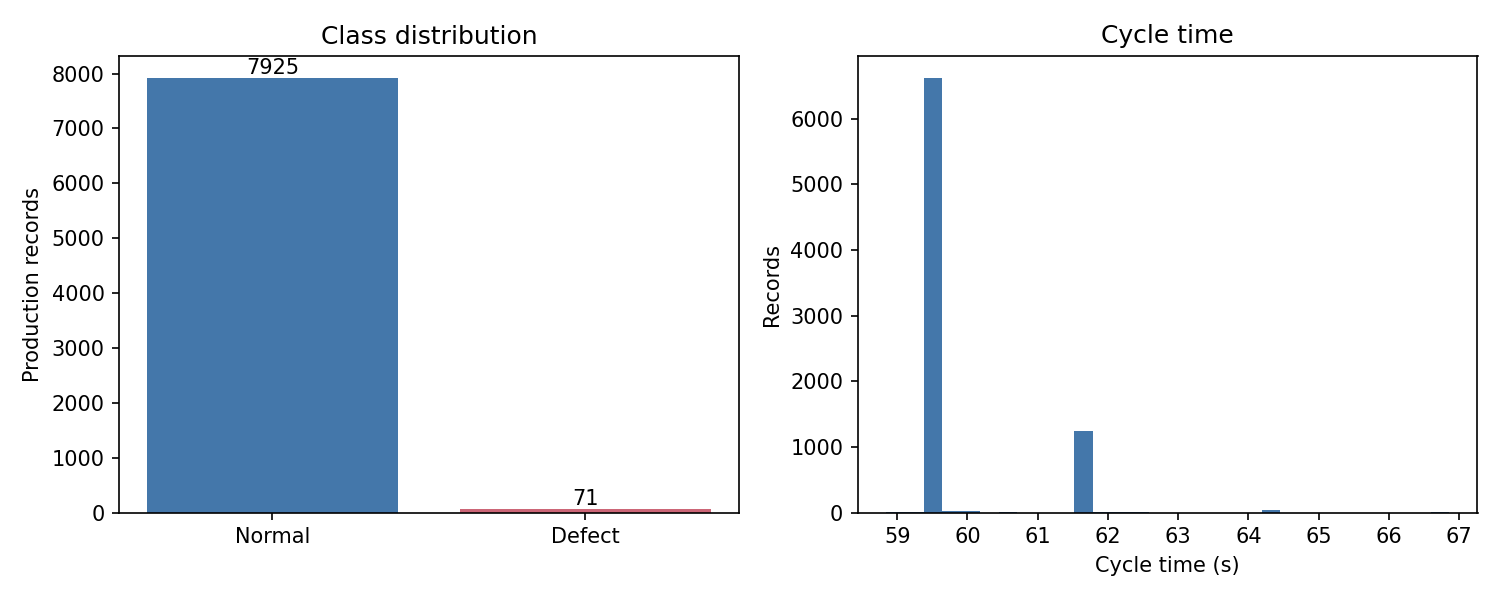

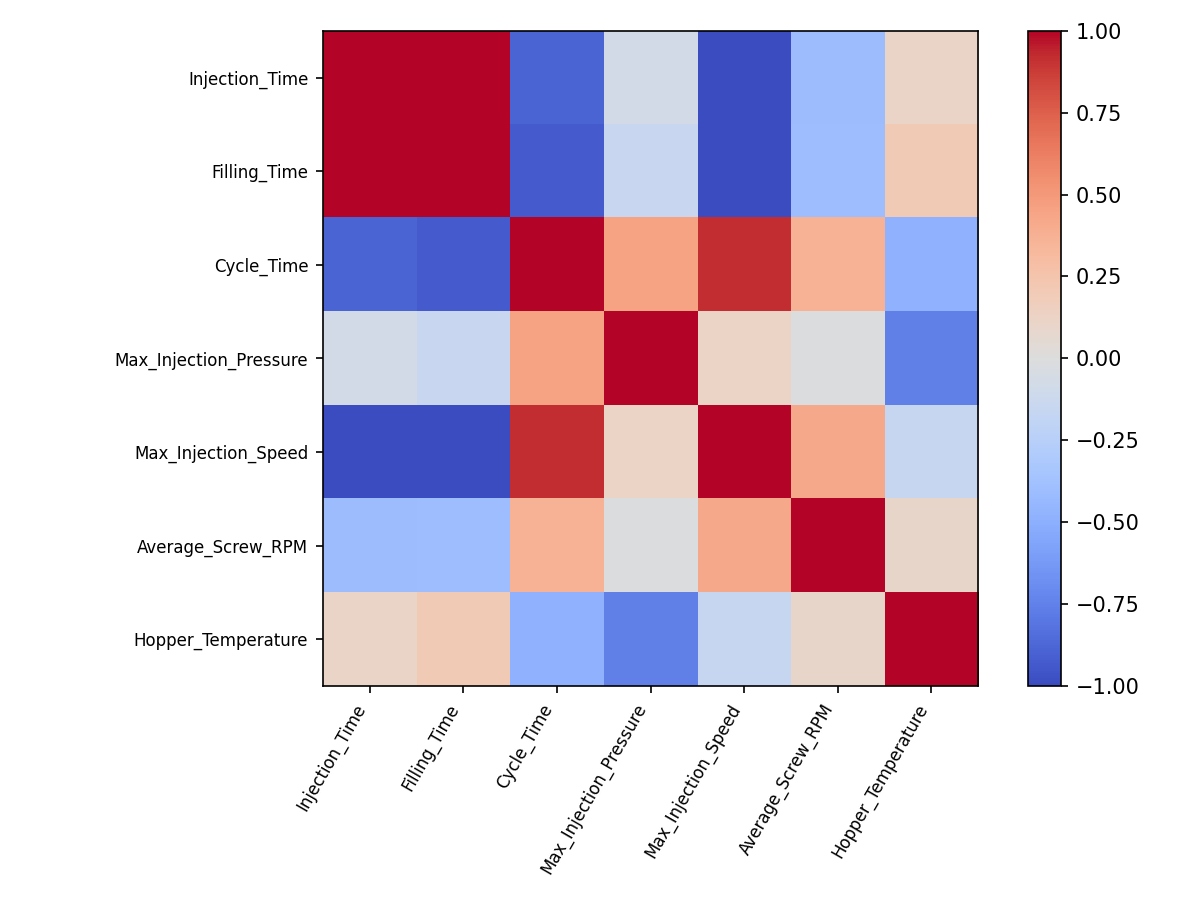

In [4]:
save_eda(data, output)
display(Image(filename=str(output / 'data_overview.png')))
display(Image(filename=str(output / 'correlations.png')))

불량 비율이 낮으므로 정확도만으로 모델을 비교하지 않는다. 상관관계는 변수 간 함께 변하는 정도이며 결함의 원인을 뜻하지 않는다.